In [94]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [95]:
df = pd.read_csv("data/USA_cars_datasets.csv")
df.head()

,Unnamed: 0,price,brand,model,year,title_status,mileage,color,vin,lot,state,country,condition
0,0,6300,toyota,cruiser,2008,clean vehicle,274117.0,black,jtezu11f88k007763,159348797,new jersey,usa,10 days left
1,1,2899,ford,se,2011,clean vehicle,190552.0,silver,2fmdk3gc4bbb02217,166951262,tennessee,usa,6 days left
2,2,5350,dodge,mpv,2018,clean vehicle,39590.0,silver,3c4pdcgg5jt346413,167655728,georgia,usa,2 days left
3,3,25000,ford,door,2014,clean vehicle,64146.0,blue,1ftfw1et4efc23745,167753855,virginia,usa,22 hours left
4,4,27700,chevrolet,1500,2018,clean vehicle,6654.0,red,3gcpcrec2jg473991,167763266,florida,usa,22 hours left


In [96]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2499 entries, 0 to 2498
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Unnamed: 0    2499 non-null   int64  
 1   price         2499 non-null   int64  
 2   brand         2499 non-null   object 
 3   model         2499 non-null   object 
 4   year          2499 non-null   int64  
 5   title_status  2499 non-null   object 
 6   mileage       2499 non-null   float64
 7   color         2499 non-null   object 
 8   vin           2499 non-null   object 
 9   lot           2499 non-null   int64  
 10  state         2499 non-null   object 
 11  country       2499 non-null   object 
 12  condition     2499 non-null   object 
dtypes: float64(1), int64(4), object(8)
memory usage: 253.9+ KB


In [97]:
# remove index
df = df.drop(columns=['Unnamed: 0'])

In [98]:
df.isna().sum()

price           0
brand           0
model           0
year            0
title_status    0
mileage         0
color           0
vin             0
lot             0
state           0
country         0
condition       0
dtype: int64

In [99]:
df.duplicated().sum()

np.int64(0)

In [100]:
df.describe()

,price,year,mileage,lot
count,2499.000000,2499.000000,2.499000e+03,2.499000e+03
mean,18767.671469,2016.714286,5.229869e+04,1.676914e+08
std,12116.094936,3.442656,5.970552e+04,2.038772e+05
min,0.000000,1973.000000,0.000000e+00,1.593488e+08
25%,10200.000000,2016.000000,2.146650e+04,1.676253e+08
50%,16900.000000,2018.000000,3.536500e+04,1.677451e+08
75%,25555.500000,2019.000000,6.347250e+04,1.677798e+08
max,84900.000000,2020.000000,1.017936e+06,1.678055e+08


In [101]:
# drop $0 prices
mask = df['price'] != 0
df = df[mask]
df['price'].describe()

count     2456.000000
mean     19096.258550
std      11962.176006
min         25.000000
25%      10500.000000
50%      17050.000000
75%      25800.000000
max      84900.000000
Name: price, dtype: float64

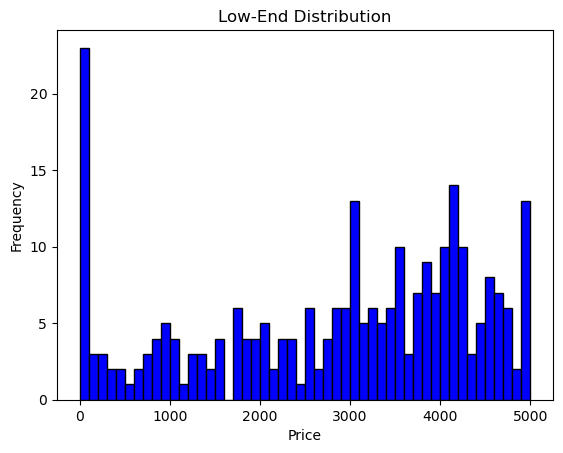

In [102]:
# price still has a minimum of 25 which is far too low
plt.hist(df['price'], bins=50, range=(0, 5000), color='blue', edgecolor='black')
plt.title('Low-End Distribution')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.show()

In [103]:
df['price'].quantile([0.01, 0.05, 0.10])

0.01     152.5
0.05    3000.0
0.10    4670.0
Name: price, dtype: float64

In [104]:
# filter out the bottom 5% of prices
mask = df['price'] > 3000
df = df[mask]
df['price'].describe()

count     2326.000000
mean     20079.491402
std      11522.172629
min       3020.000000
25%      11770.000000
50%      18000.000000
75%      26300.000000
max      84900.000000
Name: price, dtype: float64

In [105]:
# 0 mileage is not realistic for used cars, so we will filter those out
df = df[df['mileage'] > 0]
df['mileage'].describe()

count      2325.000000
mean      44986.735914
std       41763.410807
min           1.000000
25%       20681.000000
50%       34071.000000
75%       54106.000000
max      999999.000000
Name: mileage, dtype: float64

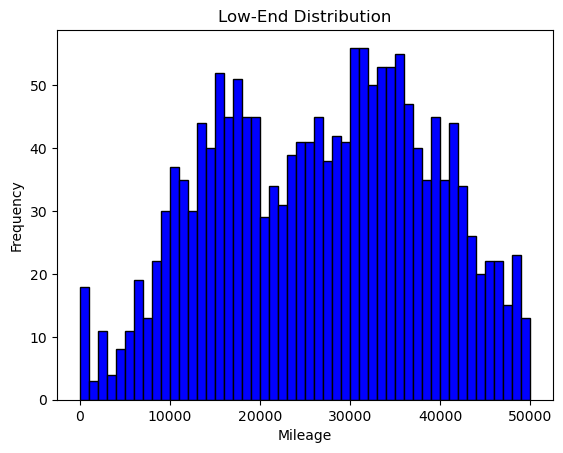

In [106]:
plt.hist(df['mileage'], bins=50, range=(0, 50000), color='blue', edgecolor='black')
plt.title('Low-End Distribution')
plt.xlabel('Mileage')
plt.ylabel('Frequency')
plt.show()

In [107]:
df['mileage'].quantile([0.01, 0.05, 0.10])

0.01     2172.32
0.05     9446.20
0.10    12781.20
Name: mileage, dtype: float64

In [108]:
# 2172.32 could be a realistic mileage for a used car, so we will filter out the bottom 1%
df = df[df['mileage'] > 2172.32]
df['mileage'].describe()

count      2301.000000
mean      45449.513255
std       41732.736203
min        2205.000000
25%       21150.000000
50%       34272.000000
75%       54309.000000
max      999999.000000
Name: mileage, dtype: float64

In [109]:
# we see that the max is incredibly high at 999999
# lets assume the used car dealership does not buy cars with more than 150,000 miles
df = df[df['mileage'] <= 150000]
df['mileage'].describe()

count      2260.000000
mean      42328.599558
std       30306.038134
min        2205.000000
25%       20892.000000
50%       33929.000000
75%       52343.750000
max      149712.000000
Name: mileage, dtype: float64

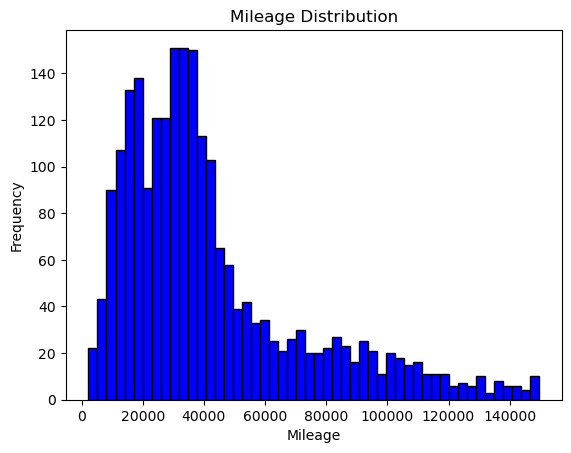

In [110]:
plt.hist(df['mileage'], bins=50, color='blue', edgecolor='black')
plt.title('Mileage Distribution')
plt.xlabel('Mileage')
plt.ylabel('Frequency')
plt.show()

In [111]:
# create mileage cohorts for easier analysis and visualization
bins = [2000, 30000, 60000, 100000, 150000]
labels = ['Low (2-30k)', 'Medium (30k-60k)', 'High (60k-100k)', 'Very High (100k-150k)']
df['mileage_cohort'] = pd.cut(df['mileage'], bins=bins, labels=labels)
print(df['mileage_cohort'].value_counts())

mileage_cohort
Low (2-30k)              920
Medium (30k-60k)         875
High (60k-100k)          301
Very High (100k-150k)    164
Name: count, dtype: int64


In [112]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2260 entries, 2 to 2498
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype   
---  ------          --------------  -----   
 0   price           2260 non-null   int64   
 1   brand           2260 non-null   object  
 2   model           2260 non-null   object  
 3   year            2260 non-null   int64   
 4   title_status    2260 non-null   object  
 5   mileage         2260 non-null   float64 
 6   color           2260 non-null   object  
 7   vin             2260 non-null   object  
 8   lot             2260 non-null   int64   
 9   state           2260 non-null   object  
 10  country         2260 non-null   object  
 11  condition       2260 non-null   object  
 12  mileage_cohort  2260 non-null   category
dtypes: category(1), float64(1), int64(3), object(8)
memory usage: 231.9+ KB


In [113]:
df.to_csv("data/cleaned_us_cars_auction.csv", index=False)